# LSTM model training and 2026 evaluation

## Academic objective

An LSTM is a recurrent neural network that uses gated state updates to carry information through a sequence. For input xₜ and previous hidden and cell states (hₜ₋₁, cₜ₋₁), the forget, input, and output gates regulate what is retained, written, and exposed. The cell update is

    cₜ = fₜ ⊙ cₜ₋₁ + iₜ ⊙ gₜ,       hₜ = oₜ ⊙ tanh(cₜ)

The project model reads a fixed 30-day window of causal features and predicts the next-day log return log(Closeₜ₊₁ / Closeₜ). The predicted return is converted back to a close-price forecast. LSTMs can model nonlinear temporal interactions, but they are data-hungry and sensitive to scaling, optimization, and regime changes. A small BTC history does not guarantee that extra complexity improves on persistence.

**Information boundary:** train on target dates through 2023, select epoch count on 2024, refit the selected architecture through 2025, and use 2026 only for final rolling one-day-ahead evaluation. The 2026 weights and hyperparameters remain frozen.

## 1. Production architecture and reproducibility

The project adapter initializes a fresh PyTorch `nn.LSTM` and a linear output head. No external weights are loaded. The monitored training loop below mirrors the adapter's architecture, flattened-sequence `StandardScaler`, target `StandardScaler`, Adam optimizer, MSE loss, seeded shuffled batches, and CPU execution. The final refit and bundle save use `LSTMForecaster` itself so the output remains compatible with production inference.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import platform
import sys
import uuid
from datetime import datetime, timezone
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "src" / "btc_forecasting").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from inside the BTC forecasting project.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from btc_forecasting.data import load_ohlcv_csv
from btc_forecasting.features import make_features
from btc_forecasting.metrics import evaluate_predictions

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

CONFIG_PATH = PROJECT_ROOT / "configs" / "default.yaml"
with CONFIG_PATH.open(encoding="utf-8") as stream:
    PROJECT_CONFIG = yaml.safe_load(stream)

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def package_version(name: str) -> str:
    try:
        return version(name)
    except PackageNotFoundError:
        return "not-installed"

def make_run_id(model_name: str) -> str:
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    return f"{stamp}_notebook_{model_name}_{uuid.uuid4().hex[:8]}"

PLOT_OUTPUTS = {}
EXTRA_TABLES = {}

def capture_plot(name, figure):
    import io
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=160, bbox_inches="tight")
    PLOT_OUTPUTS[name] = buffer.getvalue()

def save_run(model_name, run_id, predictions, metrics, validation_scores,
             configuration, model_metadata, save_model):
    """Create a new run directory and refuse every path collision."""
    run_dir = PROJECT_ROOT / "artifacts" / "runs" / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    model_dir = run_dir / "models"
    model_dir.mkdir()
    model_relative_path = save_model(model_dir)
    for name, image_bytes in PLOT_OUTPUTS.items():
        (run_dir / name).write_bytes(image_bytes)
    for name, table in EXTRA_TABLES.items():
        table.to_csv(run_dir / name, index=True)
    predictions.to_csv(run_dir / "predictions.csv", index=False)
    metrics.to_csv(run_dir / "metrics.csv", index_label="model")
    validation_scores.to_csv(run_dir / "validation_scores.csv", index=False)
    (run_dir / "configuration.json").write_text(
        json.dumps(configuration, indent=2, sort_keys=True, default=str) + "\n",
        encoding="utf-8",
    )
    metadata = {
        "run_id": run_id,
        "notebook_experiment": True,
        "notebook_model": model_name,
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_sha256": RAW_SHA256,
        "raw_data_sha256": RAW_SHA256,
        "features_sha256": FEATURES_SHA256,
        "raw_data_file": str(RAW_PATH),
        "target_column": TARGET_COLUMN,
        "horizon_days": 1,
        "prediction_index": "decision date; target date is the following calendar date",
        "split_ranges_by_target_date": SPLIT_CONFIG,
        "rows": {"train": len(TRAIN), "validation": len(VALIDATION),
                 "final_fit": len(DEVELOPMENT), "final_evaluation": len(TEST)},
        "feature_columns": FEATURE_COLUMNS,
        "model": model_metadata,
        "model_artifacts": {model_name: model_relative_path},
        "software_versions": {
            "python": platform.python_version(),
            "numpy": package_version("numpy"),
            "pandas": package_version("pandas"),
            "statsmodels": package_version("statsmodels"),
            "pmdarima": package_version("pmdarima"),
            "scikit-learn": package_version("scikit-learn"),
            "xgboost": package_version("xgboost"),
            "torch": package_version("torch"),
            "matplotlib": package_version("matplotlib"),
        },
    }
    (run_dir / "metadata.json").write_text(
        json.dumps(metadata, indent=2, sort_keys=True, default=str) + "\n",
        encoding="utf-8",
    )
    return run_dir

## 2. Data provenance and temporal partitions

The notebook uses the newest immutable OHLCV snapshot already present in `data/raw/`. It does not download or replace data. Features are rebuilt with the project's causal feature function; no feature row uses a later candle. The next-close target is kept separate from the model inputs.

Training and validation are assigned by **target date**. A row dated *t* uses information through the close on *t* and predicts *t+1*. Thus the train/validation boundary does not accidentally put a January 1 target into training merely because its decision row is dated December 31.

In [2]:
import hashlib
from btc_forecasting.features import TARGET_COLUMNS

RAW_DIRECTORY = PROJECT_ROOT / "data" / "raw"
raw_candidates = sorted(RAW_DIRECTORY.glob("*.csv"))
if not raw_candidates:
    raise FileNotFoundError("No raw OHLCV snapshots found under data/raw/.")
RAW_PATH = raw_candidates[-1]
raw = load_ohlcv_csv(RAW_PATH)
RAW_SHA256 = sha256_file(RAW_PATH)
TARGET_COLUMN = PROJECT_CONFIG["target"]["column"]
if TARGET_COLUMN != "Target_Next_Close":
    raise ValueError("These demonstrations require the project's one-day next-close target.")

frame = make_features(raw, drop_incomplete=False)
FEATURE_COLUMNS = [c for c in frame.columns if c not in TARGET_COLUMNS and not str(c).startswith("Target_")]
frame = frame.dropna(subset=FEATURE_COLUMNS).copy()
frame["Target_Date"] = frame.index + pd.Timedelta(days=1)
frame["Target_Next_Close"] = pd.to_numeric(frame["Target_Next_Close"], errors="coerce")
frame = frame.replace([np.inf, -np.inf], np.nan)
FEATURES_SHA256 = hashlib.sha256(
    frame.reset_index().to_csv(index=False, date_format="%Y-%m-%d").encode("utf-8")
).hexdigest()

SPLIT_CONFIG = {
    "training_target_dates": ["2018-01-01", "2023-12-31"],
    "validation_target_dates": ["2024-01-01", "2024-12-31"],
    "final_fit_target_dates": ["2018-01-01", "2025-12-31"],
    "final_evaluation_target_dates": ["2026-01-01", str(raw.index[-1].date())],
    "evaluation_strategy": "rolling one-day-ahead; weights and hyperparameters frozen throughout 2026",
}
target_dates = frame["Target_Date"]
has_target = frame[TARGET_COLUMN].notna()
TRAIN = frame.loc[has_target & (target_dates <= "2023-12-31")].copy()
VALIDATION = frame.loc[
    has_target & target_dates.between("2024-01-01", "2024-12-31", inclusive="both")
].copy()
DEVELOPMENT = frame.loc[has_target & (target_dates <= "2025-12-31")].copy()
TEST = frame.loc[has_target & (target_dates >= "2026-01-01")].copy()

assert not TRAIN.empty and not VALIDATION.empty and not DEVELOPMENT.empty and not TEST.empty
assert TRAIN["Target_Date"].max() <= pd.Timestamp("2023-12-31")
assert VALIDATION["Target_Date"].min() >= pd.Timestamp("2024-01-01")
assert VALIDATION["Target_Date"].max() <= pd.Timestamp("2024-12-31")
assert DEVELOPMENT["Target_Date"].max() <= pd.Timestamp("2025-12-31")
assert TEST["Target_Date"].min() >= pd.Timestamp("2026-01-01")
assert TEST["Target_Date"].max() <= raw.index[-1]

print(f"Raw source: {RAW_PATH}")
print(f"Raw SHA-256: {RAW_SHA256}")
print(f"Feature SHA-256: {FEATURES_SHA256}")
print(f"Latest observed BTC close date: {raw.index[-1].date()}")
print(f"Last target date with an actual next close: {TEST['Target_Date'].max().date()}")
display(pd.DataFrame([
    {"partition": "Train", "first_target_date": TRAIN.Target_Date.min().date(),
     "last_target_date": TRAIN.Target_Date.max().date(), "rows": len(TRAIN)},
    {"partition": "Validation", "first_target_date": VALIDATION.Target_Date.min().date(),
     "last_target_date": VALIDATION.Target_Date.max().date(), "rows": len(VALIDATION)},
    {"partition": "Final model fit", "first_target_date": DEVELOPMENT.Target_Date.min().date(),
     "last_target_date": DEVELOPMENT.Target_Date.max().date(), "rows": len(DEVELOPMENT)},
    {"partition": "Unseen 2026 evaluation", "first_target_date": TEST.Target_Date.min().date(),
     "last_target_date": TEST.Target_Date.max().date(), "rows": len(TEST)},
]))

feature_columns = FEATURE_COLUMNS
train = TRAIN
validation = VALIDATION
development = DEVELOPMENT
test = TEST

Raw source: C:\Users\Manya Chaubey\Downloads\Crypto\data\raw\BTC-USD_20180101_20261114_20261115T172122Z.csv
Raw SHA-256: deb1ce1e9955cfb8290783516159e9519c7337f3fb95e320401332d622a18e87
Feature SHA-256: 1210f3dd28aceb38e2d22859c4fd2fd7de19b7850f7c2bc4002f6b7a7d1f0533
Latest observed BTC close date: 2026-11-14
Last target date with an actual next close: 2026-11-14


,partition,first_target_date,last_target_date,rows
0,Train,2018-07-20,2023-12-31,1991
1,Validation,2024-01-01,2024-12-31,366
2,Final model fit,2018-07-20,2025-12-31,2722
3,Unseen 2026 evaluation,2026-01-01,2026-11-14,318


## 3. Build causal lookback windows

A sequence ending on decision date *t* contains features from *t−29* through *t*. Its label is the next-day log return for that row. Training and validation labels are selected by target date, while validation windows may use the preceding observed training features as context. No future feature enters a window.

In [3]:
from scripts.run_experiment import _build_lstm_sequences
from btc_forecasting.models.lstm import LSTMForecaster

lstm_config = PROJECT_CONFIG["lstm"]
LOOKBACK = int(lstm_config["lookback"])
all_sequences, sequence_index, log_returns = _build_lstm_sequences(
    frame,
    FEATURE_COLUMNS,
    target_column=TARGET_COLUMN,
    lookback=LOOKBACK,
)
sequence_positions = pd.Series(range(len(sequence_index)), index=sequence_index)
train_index = TRAIN.index.intersection(sequence_index, sort=False)
validation_index = VALIDATION.index.intersection(sequence_index, sort=False)
development_index = DEVELOPMENT.index.intersection(sequence_index, sort=False)
test_index = TEST.index.intersection(sequence_index, sort=False)
assert test_index.equals(TEST.index)
train_positions = sequence_positions.loc[train_index].to_numpy()
validation_positions = sequence_positions.loc[validation_index].to_numpy()
development_positions = sequence_positions.loc[development_index].to_numpy()
test_positions = sequence_positions.loc[test_index].to_numpy()
X_train = all_sequences[train_positions]
y_train = log_returns.loc[train_index]
X_validation = all_sequences[validation_positions]
y_validation = log_returns.loc[validation_index]

## 4. Initialize the architecture and log each epoch

To expose genuine training and validation curves, train once for the maximum candidate epoch count and record the validation score at every epoch. With identical initialization and seeded mini-batch order, the state at candidate epoch *e* matches a fresh project-adapter fit for *e* epochs. Candidate selection uses validation RMSE after converting predictions into USD closes. The validation loss displayed is standardized-target MSE; the RMSE table is in dollars.

,epoch,training_loss_scaled_mse,validation_loss_scaled_mse,validation_rmse_usd
9,10,0.880049,0.717693,2005.591759
19,20,0.681050,1.211119,2613.287804
29,30,0.506000,1.035593,2369.265046


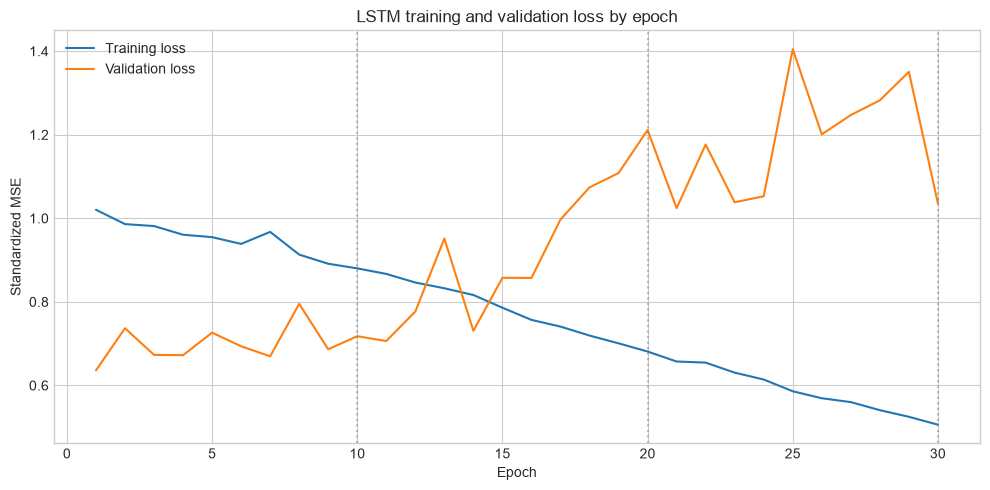

,epochs,rmse,selected
9,10,2005.5918,True
19,20,2613.2878,False
29,30,2369.2650,False


Selected epoch count by 2024 validation RMSE: 10


In [4]:
import copy
import torch
from sklearn.preprocessing import StandardScaler

torch.set_num_threads(1)
base_parameters = {
    key: lstm_config[key]
    for key in ("hidden_size", "num_layers", "dropout", "learning_rate", "batch_size", "random_state")
}
candidate_epochs = [int(value) for value in lstm_config["epochs_candidates"]]
MAX_EPOCHS = max(candidate_epochs)

def train_lstm_with_epoch_logs(X_train, y_train, X_val, y_val, parameters, candidate_epochs):
    """Training loop aligned with LSTMForecaster.fit, with validation logging."""
    torch.manual_seed(int(parameters["random_state"]))
    x_scaler = StandardScaler()
    x_train_scaled = x_scaler.fit_transform(
        X_train.reshape(-1, X_train.shape[-1]).astype(np.float64)
    ).reshape(X_train.shape).astype(np.float32)
    x_val_scaled = x_scaler.transform(
        X_val.reshape(-1, X_val.shape[-1]).astype(np.float64)
    ).reshape(X_val.shape).astype(np.float32)
    y_scaler = StandardScaler()
    y_train_scaled = y_scaler.fit_transform(np.asarray(y_train).reshape(-1, 1)).astype(np.float32)
    y_val_scaled = y_scaler.transform(np.asarray(y_val).reshape(-1, 1)).astype(np.float32)

    adapter = LSTMForecaster(**parameters, epochs=MAX_EPOCHS)
    model = adapter._make_model(torch, input_size=X_train.shape[-1])()
    optimizer = torch.optim.Adam(model.parameters(), lr=parameters["learning_rate"])
    loss_fn = torch.nn.MSELoss()
    tx = torch.from_numpy(x_train_scaled)
    ty = torch.from_numpy(y_train_scaled)
    generator = torch.Generator().manual_seed(int(parameters["random_state"]))
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(tx, ty), batch_size=int(parameters["batch_size"]),
        shuffle=True, generator=generator,
    )
    vx = torch.from_numpy(x_val_scaled)
    vy = torch.from_numpy(y_val_scaled)
    records = []
    candidate_states = {}
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        batch_losses = []
        for batch_x, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            predicted = model(batch_x)
            loss = loss_fn(predicted, batch_y)
            loss.backward()
            optimizer.step()
            batch_losses.append(float(loss.detach()))
        model.eval()
        with torch.no_grad():
            val_loss = float(loss_fn(model(vx), vy))
            val_scaled_prediction = model(vx).cpu().numpy()
        log_return_prediction = y_scaler.inverse_transform(val_scaled_prediction).reshape(-1)
        validation_close = VALIDATION.loc[validation_index, "Close"].to_numpy(dtype=float)
        predicted_close = validation_close * np.exp(log_return_prediction)
        actual_close = VALIDATION.loc[validation_index, TARGET_COLUMN].to_numpy(dtype=float)
        val_rmse_usd = float(np.sqrt(np.mean((predicted_close - actual_close) ** 2)))
        records.append({"epoch": epoch, "training_loss_scaled_mse": float(np.mean(batch_losses)),
                        "validation_loss_scaled_mse": val_loss, "validation_rmse_usd": val_rmse_usd})
        if epoch in candidate_epochs:
            candidate_states[epoch] = copy.deepcopy(model.state_dict())
    return pd.DataFrame(records), candidate_states

training_log, candidate_states = train_lstm_with_epoch_logs(
    X_train, y_train, X_validation, y_validation, base_parameters, candidate_epochs
)
display(training_log.loc[training_log["epoch"].isin(candidate_epochs)].round(6))
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(training_log["epoch"], training_log["training_loss_scaled_mse"], label="Training loss")
ax.plot(training_log["epoch"], training_log["validation_loss_scaled_mse"], label="Validation loss")
for epoch in candidate_epochs:
    ax.axvline(epoch, color="gray", linestyle=":", alpha=0.5)
ax.set_title("LSTM training and validation loss by epoch")
ax.set_xlabel("Epoch")
ax.set_ylabel("Standardized MSE")
ax.legend()
fig.tight_layout()
capture_plot("training_validation_loss.png", fig)
display(fig)
plt.close(fig)

validation_scores = training_log.loc[training_log["epoch"].isin(candidate_epochs),
                                     ["epoch", "validation_rmse_usd"]].copy()
validation_scores = validation_scores.rename(columns={"epoch": "epochs", "validation_rmse_usd": "rmse"})
best_epochs = int(validation_scores.sort_values("rmse").iloc[0]["epochs"])
validation_scores["selected"] = validation_scores["epochs"].eq(best_epochs)
display(validation_scores.round(4))
print(f"Selected epoch count by 2024 validation RMSE: {best_epochs}")

## 5. Final refit through December 31, 2025

The production adapter now trains a fresh LSTM for the selected number of epochs using every labeled target through 2025. Its feature and target scalers are fit only on those development sequences. During 2026, the model and scalers stay frozen; causal feature windows advance as new daily candles become observable.

2026 final evaluation, USD close-price errors:


,mae,rmse,directional_accuracy
LSTM,1208.5267,1752.0206,0.4748


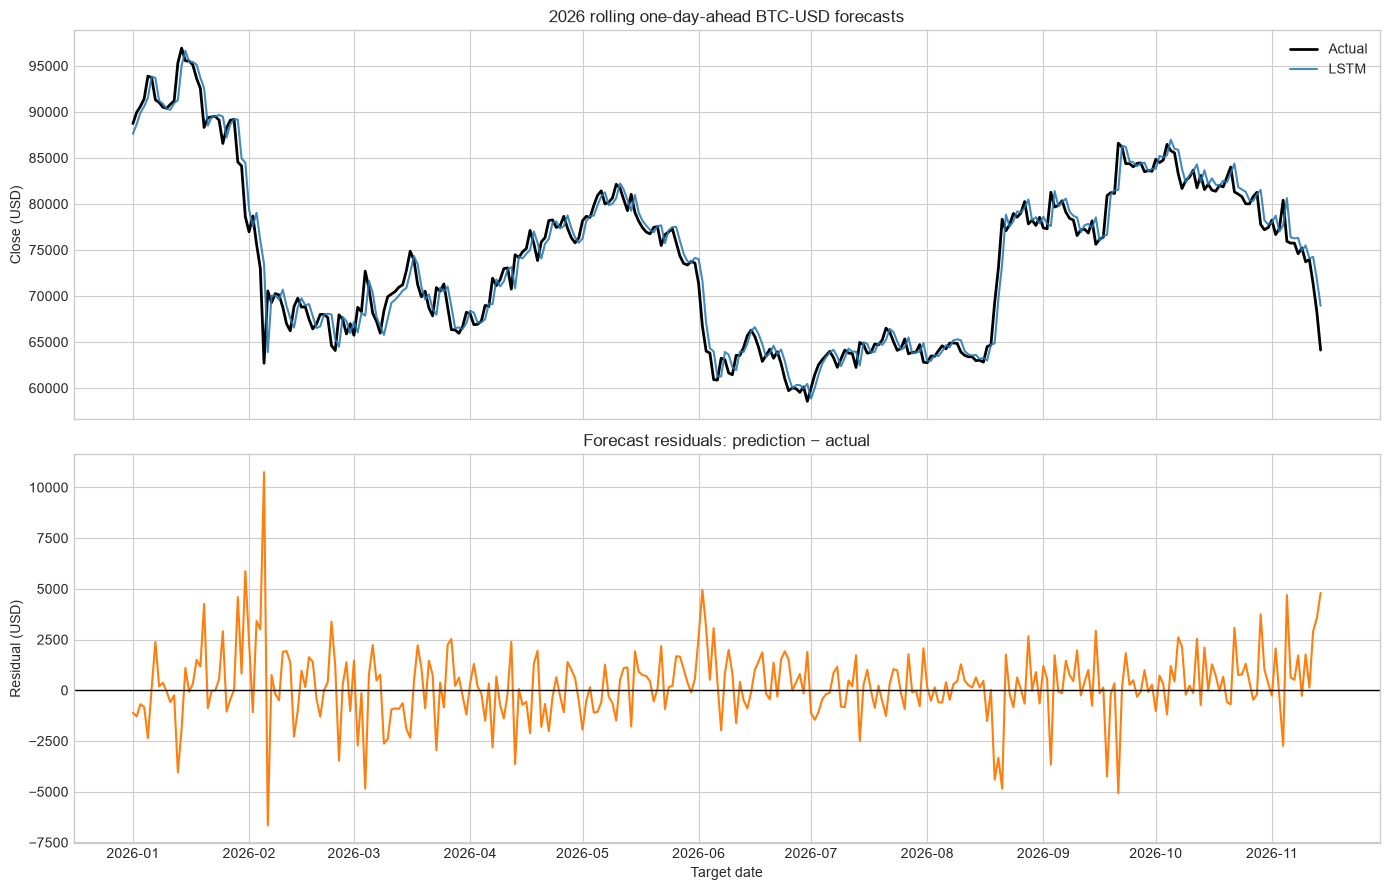

In [5]:
final_lstm = LSTMForecaster(epochs=best_epochs, **base_parameters).fit(
    all_sequences[development_positions], log_returns.loc[development_index]
)
lstm_log_return_prediction = final_lstm.predict(
    all_sequences[test_positions], index=test_index
)
lstm_prediction = TEST.loc[test_index, "Close"] * np.exp(lstm_log_return_prediction)
lstm_metrics = evaluate_predictions(
    TEST.loc[test_index, TARGET_COLUMN], lstm_prediction, TEST.loc[test_index, "Close"]
)
print("2026 final evaluation, USD close-price errors:")
display(pd.DataFrame([lstm_metrics], index=["LSTM"]).round(4))

predictions = pd.DataFrame({
    "decision_date": test_index,
    "Target_Date": TEST.loc[test_index, "Target_Date"].to_numpy(),
    "previous_close_usd": TEST.loc[test_index, "Close"].to_numpy(),
    "actual_next_close_usd": TEST.loc[test_index, TARGET_COLUMN].to_numpy(),
    "prediction_usd": lstm_prediction.to_numpy(),
})
residuals = predictions["prediction_usd"] - predictions["actual_next_close_usd"]
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
axes[0].plot(predictions["Target_Date"], predictions["actual_next_close_usd"],
             label="Actual", color="black", linewidth=2)
axes[0].plot(predictions["Target_Date"], predictions["prediction_usd"],
             label="LSTM", alpha=0.85)
axes[0].set_title("2026 rolling one-day-ahead BTC-USD forecasts")
axes[0].set_ylabel("Close (USD)")
axes[0].legend()
axes[1].plot(predictions["Target_Date"], residuals, color="tab:orange")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Forecast residuals: prediction − actual")
axes[1].set_ylabel("Residual (USD)")
axes[1].set_xlabel("Target date")
fig.tight_layout()
capture_plot("2026_forecast_and_residuals.png", fig)
display(fig)
plt.close(fig)

## 6. Architecture, trainable parameters, and learned weights

The displayed module is the actual trained PyTorch network. The parameter count is computed from tensors in the fitted model rather than estimated from a diagram. The table summarizes learned tensor values without dumping thousands of numbers into the notebook.

In [6]:
print(final_lstm._model)
trainable_parameters = sum(p.numel() for p in final_lstm._model.parameters() if p.requires_grad)
print(f"Trainable parameter count: {trainable_parameters:,}")
weight_summary = []
for name, tensor in final_lstm._model.state_dict().items():
    values = tensor.detach().cpu().numpy().astype(float)
    weight_summary.append({"tensor": name, "shape": tuple(values.shape),
                           "mean": float(values.mean()), "std": float(values.std()),
                           "minimum": float(values.min()), "maximum": float(values.max())})
display(pd.DataFrame(weight_summary))

SequenceRegressor(
  (recurrent): LSTM(79, 32, batch_first=True)
  (output): Linear(in_features=32, out_features=1, bias=True)
)
Trainable parameter count: 14,497


,tensor,shape,mean,std,minimum,maximum
0,recurrent.weight_ih_l0,"(128, 79)",-0.000527,0.108398,-0.279351,0.316433
1,recurrent.weight_hh_l0,"(128, 32)",-0.000636,0.108496,-0.287457,0.286972
2,recurrent.bias_ih_l0,"(128,)",0.009331,0.108605,-0.182449,0.220000
3,recurrent.bias_hh_l0,"(128,)",0.018591,0.105566,-0.188093,0.210693
4,output.weight,"(1, 32)",-0.002654,0.145194,-0.218228,0.203587
5,output.bias,"(1,)",0.061657,0.000000,0.061657,0.061657


## 7. Save the bundle and verify production loading

The final bundle contains trained state, scalers, sequence shape, and initialization parameters. It is saved under a new, collision-checked experiment folder. Then the same `LSTMForecaster.load` implementation used by the API reloads the artifact and reproduces the first 10 2026 predictions.

In [7]:
EXTRA_TABLES["learned_weight_summary.csv"] = pd.DataFrame(weight_summary).set_index("tensor")
EXTRA_TABLES["training_loss_per_epoch.csv"] = training_log.set_index("epoch")
RUN_ID = make_run_id("lstm")
LSTM_CONFIG = {
    "lookback": LOOKBACK,
    "candidate_epochs": candidate_epochs,
    "selected_epochs": best_epochs,
    "selection_metric": "2024 validation RMSE in USD",
    "final_fit_target_end": "2025-12-31",
    "final_evaluation": "2026 rolling one-day-ahead; no refitting or tuning",
    "parameters": {**base_parameters, "epochs": best_epochs},
}
lstm_metadata = {
    "lstm": {
        "sequence_length": LOOKBACK,
        "selected_epochs": best_epochs,
        "selection_metric": "2024 validation RMSE in USD",
        "parameters": {**base_parameters, "epochs": best_epochs},
        "refit_during_2026": False,
    }
}
LSTM_METRICS = pd.DataFrame([lstm_metrics], index=["lstm"])

def save_lstm_artifact(model_dir):
    final_lstm.save(model_dir / "lstm.joblib")
    return "models/lstm.joblib"

RUN_DIR = save_run("lstm", RUN_ID, predictions, LSTM_METRICS,
                   validation_scores, LSTM_CONFIG, lstm_metadata, save_lstm_artifact)
loaded_lstm = LSTMForecaster.load(RUN_DIR / "models" / "lstm.joblib")
round_trip = loaded_lstm.predict(all_sequences[test_positions[:10]])
assert np.allclose(round_trip.to_numpy(), lstm_log_return_prediction.iloc[:10].to_numpy(),
                   rtol=1e-6, atol=1e-6)
from btc_forecasting.api.service import _cached_model
production_lstm = _cached_model("lstm", RUN_DIR / "models" / "lstm.joblib",
                                json.loads((RUN_DIR / "metadata.json").read_text(encoding="utf-8")))
assert np.allclose(production_lstm.predict(all_sequences[test_positions[:10]]).to_numpy(),
                   lstm_log_return_prediction.iloc[:10].to_numpy(), rtol=1e-6, atol=1e-6)
print(f"Saved production-compatible bundle: {RUN_DIR / 'models' / 'lstm.joblib'}")
print("Production API loader and LSTM adapter reload checks: passed on 10 2026 examples.")

Saved production-compatible bundle: C:\Users\Manya Chaubey\Downloads\Crypto\artifacts\runs\20261115T175713292845Z_notebook_lstm_4b67ea32\models\lstm.joblib
Production API loader and LSTM adapter reload checks: passed on 10 2026 examples.


## Rolling one-day-ahead versus a fixed 365-day forecast

**Rolling one-day-ahead (used here):** at each decision date, predict only the next close using information then available. Once that date has passed and its close is observed, it may enter later causal features or update ARIMA's state. The learned XGBoost/LSTM parameters and selected hyperparameters remain fixed throughout 2026; ARIMA parameters remain fixed while its state receives already-observed closes. This estimates a repeated operational one-day forecast.

**Fixed-origin 365-day forecast:** at a single origin such as December 31, 2025, produce all forecasts through 2026 without observing any 2026 close between steps. This measures a long-horizon path and requires recursive features or a model that directly predicts all horizons. The existing XGBoost/LSTM one-step feature set cannot produce that path honestly because future OHLCV indicators are unknown. These notebooks therefore do not label rolling forecasts as a 365-day fixed-origin forecast.

The 2026 evaluation ends at the last date with an actual next close in the available raw dataset. Scores describe only that observed interval and should not be generalized to the full calendar year if later dates are unavailable.

## 8. Rolling evaluation and three-model comparison

The comparison cell below reads only completed notebook experiment folders with the same raw-data hash and the same target-date evaluation window. Run all three training notebooks first, then execute this cell in any notebook to refresh the shared comparison. It recomputes metrics from the saved per-date forecasts, verifies that actuals and target dates match, and saves a comparison table and plot in this notebook's unique experiment folder.

,mae,rmse,directional_accuracy
model,,,
arima,1181.2662,1728.3102,0.4874
xgboost,1892.7047,2454.6569,0.4811
lstm,1208.5267,1752.0206,0.4748


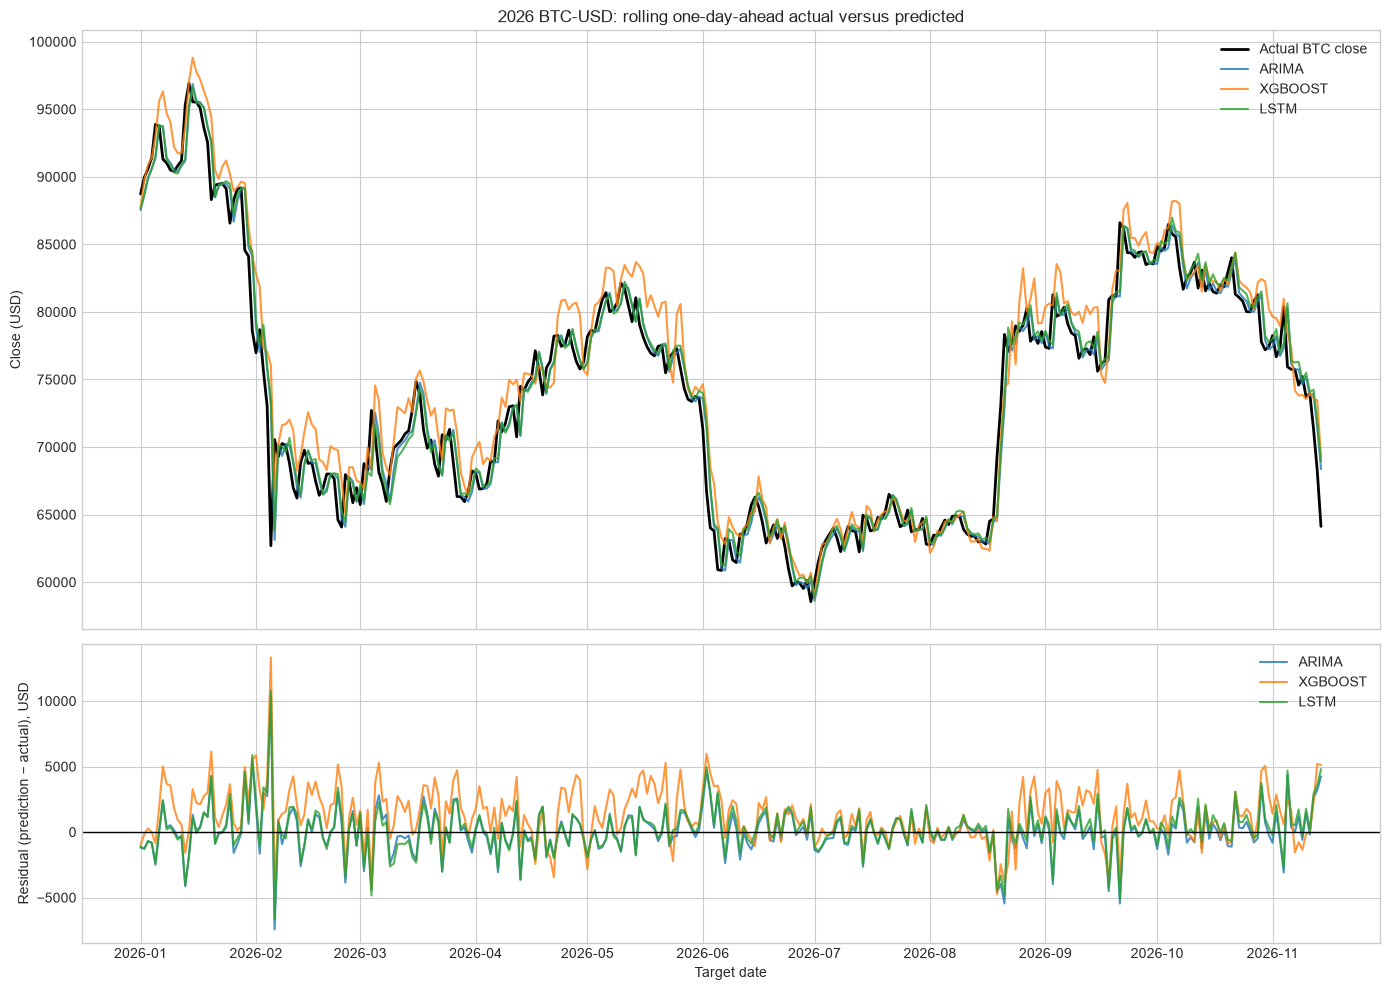

In [8]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from btc_forecasting.evaluation import compare_predictions

run_root = PROJECT_ROOT / "artifacts" / "runs"
matching_runs = {"arima": [], "xgboost": [], "lstm": []}
for candidate in run_root.iterdir() if run_root.exists() else []:
    if not candidate.is_dir():
        continue
    try:
        meta = json.loads((candidate / "metadata.json").read_text(encoding="utf-8"))
        model_name = meta.get("notebook_model")
        if (meta.get("notebook_experiment") and model_name in matching_runs
                and meta.get("raw_data_sha256") == RAW_SHA256
                and meta.get("split_ranges_by_target_date", {}).get("final_evaluation_target_dates") == SPLIT_CONFIG["final_evaluation_target_dates"]):
            matching_runs[model_name].append((candidate, meta))
    except (OSError, json.JSONDecodeError):
        continue

missing_models = [name for name, choices in matching_runs.items() if not choices]
if missing_models:
    print("Run the remaining model notebook(s), then re-execute this comparison cell: "
          + ", ".join(missing_models))
else:
    selected_runs = {
        name: sorted(choices, key=lambda item: item[0].name)[-1]
        for name, choices in matching_runs.items()
    }
    prediction_tables = {}
    for name, (folder, meta) in selected_runs.items():
        table = pd.read_csv(folder / "predictions.csv")
        table["Target_Date"] = pd.to_datetime(table["Target_Date"])
        table = table.set_index("Target_Date").sort_index()
        prediction_tables[name] = table
    common_dates = prediction_tables["arima"].index
    for table in prediction_tables.values():
        if not table.index.equals(common_dates):
            raise ValueError("The model runs do not cover exactly the same 2026 target dates.")
        if not np.allclose(table["actual_next_close_usd"], prediction_tables["arima"]["actual_next_close_usd"]):
            raise ValueError("The saved model runs disagree on actual close values.")
    actual = prediction_tables["arima"]["actual_next_close_usd"]
    previous = prediction_tables["arima"]["previous_close_usd"]
    forecasts = {
        name: table["prediction_usd"].rename(name)
        for name, table in prediction_tables.items()
    }
    comparison = compare_predictions(actual, previous, forecasts)
    display(comparison.round(4))
    comparison.to_csv(RUN_DIR / "three_model_comparison_2026.csv", index_label="model")

    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
    axes[0].plot(actual.index, actual, label="Actual BTC close", color="black", linewidth=2)
    for name, forecast in forecasts.items():
        axes[0].plot(forecast.index, forecast, label=name.upper(), alpha=0.8)
        axes[1].plot(forecast.index, forecast - actual, label=name.upper(), alpha=0.8)
    axes[0].set_title("2026 BTC-USD: rolling one-day-ahead actual versus predicted")
    axes[0].set_ylabel("Close (USD)")
    axes[0].legend()
    axes[1].axhline(0, color="black", linewidth=1)
    axes[1].set_ylabel("Residual (prediction − actual), USD")
    axes[1].set_xlabel("Target date")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / "three_model_comparison_2026.png", dpi=160)
    display(fig)
    plt.close(fig)